# Supplementary Figure 9 a-c, panels (i) and (ii)

**M2 mean activation amplitude bar plots, standard ROI averaging vs CLS-derived.**

| panel | caption wording | data source |
|---|---|---|
| **(i)** | "standard ROI averaging" | `dict_all_data['TCs_matrix']` |
| **(ii)** | "CLS-derived components" | `dict_all_data['H_nnls_bouts']` |

`TCs_matrix` is the ROI-averaged time-course matrix that is fed *into* the constrained-NNLS
fit; `H_nnls_bouts` is what comes *out* of it. Both are (42 regions x time x bouts), indexed
by the pickle's own `all_bdps`. Panel (ii) is the same quantity main Fig 7 plots -- this
notebook asserts that (`H_nnls_bouts` M2 rows == `array_M2`) rather than assuming it.

### Why this notebook exists

These panels had no source file anywhere in the repository:

* `figure-S9.ipynb` contains **only panels d and e**.
* Fig 7's `part4` cells plot S1 + M1 + M2 into **one combined figure** and export only that
  composite -- the M2-only panel the Suppl Fig 9 layout needs was never exported.
* `make_0_prepare/CLS-VALIDATION/forward_pass_validation/figure7-validation(refined).ipynb`
  does compute the `TCs_matrix` (panel i) version, but it exports only combined figures and
  it still contains the cross-mouse accumulation bug described below.

This notebook renders them, reusing Fig 7's exact `part4` geometry and styling so the output
drops in side-by-side with Fig 7's panels at identical type and mark size.

## Correctness notes

### 1. The bug this notebook does not reproduce

Cells 5 / 18 / 29 of `figure-7(refined).ipynb` originally sliced `amplitude_data_dict[mouse]`
out of the running `array_S1` / `array_M2` / `array_M1` accumulators **without resetting
them**, so the 2nd and 3rd mouse of each movement type silently absorbed every earlier
mouse's bouts. `figure-7(refined).ipynb` has since been fixed (see its `# FIX:` comments).
The `CLS-VALIDATION` copy has **not** been fixed and still yields, for licking,
cm229 = 19 / cm241 = 31 (19+12) / cm242 = 44 (19+12+13).

Here every mouse's amplitudes are computed from **its own bouts only**.

### 2. Bout selection -- the published (`figure6`) generation is authoritative for N

Only `figure7`'s pickles carry `TCs_matrix` (needed for panel i); `figure6`'s do not. The two
generations agree on every mouse **except cm229 / licking**, where `figure7` has 19 bouts and
`figure6` has 18. `figure6`'s 18 are an *exact subset* of `figure7`'s 19 -- bouts 0-14 map
identically, then 15, 16, 17 -> 16, 17, 18 -- so **`figure7` bout index 15 is an extra** that
the published generation excludes. Dropping it gives the caption's N = 43 (18/12/13) and
makes panels (i) and (ii) use *identical* bouts.

The drop is applied **only** when the source generation actually carries the extra bout, and
a hard assert requires each mouse's final count to equal the published `figure6` count.

### 3. Caption vs data (not changed by this notebook -- for the manuscript)

| panel | caption | data on disk | verdict |
|---|---|---|---|
| **a** locomotion | N = 126 (40/34/52) | **N = 191 (39/100/52)** | caption **stale** |
| **b** licking | N = 43 (18/12/13) | N = 43 (18/12/13) | caption **correct** |
| **c** multi-effector | N = 48 (16/15/17) | **N = 38 (16/15/7)** | caption **stale** |

*Panel a*: cm125's own curation notebook
(`make_0_prepare/CLS-all-mice/cm125/0518-SE-V3-step2-run-cm125(refined).ipynb`, cell 8)
carries a commented-out `[:,:100:3]` slice next to the note *"downsize by 3 to save space --
actually reverse"*, and `len(range(0, 100, 3)) == 34` exactly. cm126's sibling notebook still
has the identical commented `#[:,:100:3]` line. So 126 traces to a superseded generation that
truncated cm125 to 34 bouts before reverting to the full 100; no dataset with 40/34/52 exists
on disk. cm126 = 52 matches either way because it is never sliced.

*Panel c*: cm128 has 7 bouts in every copy on disk, and its curation notebook hand-lists
exactly 7 by index -- not a filter that could be loosened.

### 4. Data provenance

`movie8/` is a **visualization cache, not part of the publication chain**, and is deliberately
not used as a source anywhere below.

| mouse / panel | source |
|---|---|
| all mice, panel (i) except integrated cm126/cm128 | `figures_data/figure7` `TCs_matrix` |
| all mice, panel (ii) | `figures_data/figure6` `H_nnls_bouts` (the published generation) |
| integrated **cm126**, panel (i) | `figure_S9/dict_integrate_candidates/dict_all_integrated_cm126(2)` |
| integrated **cm128**, panel (i) | `figures_data/figureS9/TCs_matrix_integrated_cm128` (recomputed) |

**cm126**: the candidate file was verified key-by-key against the deposited pickle --
identical `H_nnls_bouts`, `array_S1/M2/M1`, `AVG_full_jrgeco_2_save`, `blended_movie_2_save`,
`T_PRE_rise`, `T_PRE_lick`, `all_bdps`. It is the same generation, saved *with* the
`TCs_matrix` key.

**cm128**: no saved `TCs_matrix` exists anywhere on disk (confirmed by byte-level grep for the
string across every pickle under `/Volumes/WX`; the only cm128 hit is
`prepares_data/CLS/M2S1M1_NNLS_spatial_cm128`, whose `TCs_matrix` is shape (42, 4272) -- the
full training-bout concatenation, a different object). Root cause is a two-branch divergence:
`CLS-all-mice/cm128/...ipynb` computes `TCs_matrix` but **omits it from the saved dict** and is
what wrote the deposited pickle, while the `CLS-VALIDATION` copy includes the key but was never
run for cm128. It is therefore recomputed from raw `step_1` data in the appendix section below.

In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE

In [2]:
import pickle
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter

sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

# Two warning families are expected here and are silenced so the checks below stay readable:
#  * seaborn FutureWarning about `palette` without `hue` -- kept deliberately, because these
#    barplot/stripplot calls are copied verbatim from Fig 7's part4 cells and must stay
#    byte-for-byte equivalent to them for the side-by-side comparison to be meaningful.
#  * numpy "Mean of empty slice" -- the seed-ROI boxes and 500-parcel masks legitimately
#    contain all-NaN columns outside the brain mask; nanmean over them is intended.
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice')

HERE = CODE / 'make_1_figures' / 'figure_S9'
CANDIDATES = HERE / 'dict_integrate_candidates'
OUTDIR = HERE / '_corrected'
OUTDIR.mkdir(parents=True, exist_ok=True)

palatte_dict = load_pickle(str(PREPARES / 'config') + '/palatte_dict')

# physical row order of the M2 amplitude matrix -- same across mice, as in Fig 7's own cells
M2_ORDER = ['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP']

## Configuration

Movement/amplitude windows are copied from Fig 7's own assembly cells (5 = lick, 18 = run,
29 = integrated). The y-axis limits are copied from the **M2 axis (`ax2`)** of Fig 7's
`part4` cells (13 = lick, 23 = run, 36 = integrated) -- these differ per panel column, so
using one column's limits everywhere squashes the other two.

In [3]:
# movement window + amplitude-averaging window, from Fig 7 cells 5 / 18 / 29
MOVEMENT = {
    'run':        dict(mice=['cm229', 'cm125', 'cm126'],
                       t_range=lambda d: np.arange(d['T_PRE'] - 30, d['T_PRE'] + 80),
                       ind=range(30, 70)),
    'lick':       dict(mice=['cm229', 'cm241', 'cm242'],
                       t_range=lambda d: np.arange(d['T_PRE'] - 18, d['T_PRE'] + 18),
                       ind=range(18, 28)),
    'integrated': dict(mice=['cm229', 'cm126', 'cm128'],
                       t_range=lambda d: np.arange(8, 58),
                       ind=range(8, 38)),
}

# y-axis per column, from the M2 axis (ax2) of Fig 7's part4 cells
YAXIS = {
    'run':        dict(ylim=[-0.015, 0.15],  yticks=[0.00, 0.1]),   # panel a -> 0% / 10%
    'lick':       dict(ylim=[-0.01,  0.05],  yticks=[0.00, 0.04]),  # panel b -> 0% / 4%
    'integrated': dict(ylim=[-0.02,  0.055], yticks=[0.00, 0.04]),  # panel c -> 0% / 4%
}

PANEL_KEY = {'i': 'TCs_matrix', 'ii': 'H_nnls_bouts'}

# figure7 carries one extra cm229 licking bout that the published figure6 generation excludes
EXTRA_BOUTS = {('lick', 'cm229'): [15]}

PANEL_LABEL = {'run': 'a  locomotion', 'lick': 'b  licking during locomotion',
               'integrated': 'c  multi-effector motif'}

## Loading, with provenance

In [4]:
def source_matrix(movement, mouse, panel):
    '''Return (matrix_42xTxB, all_bdps, provenance_label). No movie8 in any path.'''
    if panel == 'i' and movement == 'integrated':
        if mouse == 'cm126':
            c = load_pickle(str(CANDIDATES / 'dict_all_integrated_cm126(2)'))
            c = c.get('dict_all_data', c)
            return np.asarray(c['TCs_matrix']), list(c['all_bdps']), 'candidates/cm126(2)'
        if mouse == 'cm128':
            dep = load_pickle(f'{FIGURES}/figure7/dict_all_integrated_cm128')['dict_all_data']
            tcs = np.asarray(load_pickle(f'{FIGURES}/figureS9/TCs_matrix_integrated_cm128'))
            return tcs, list(dep['all_bdps']), 'figureS9/recomputed-from-raw'

    generation = 'figure7' if panel == 'i' else 'figure6'
    d = load_pickle(f'{FIGURES}/{generation}/dict_all_{movement}_{mouse}')['dict_all_data']
    return np.asarray(d[PANEL_KEY[panel]]), list(d['all_bdps']), f'{generation}[{PANEL_KEY[panel]}]'


def keep_bouts(movement, mouse, n_source, n_published):
    '''Drop extra bout(s) only when the source generation actually carries them.'''
    if n_source == n_published:
        return list(range(n_source))
    extra = EXTRA_BOUTS.get((movement, mouse), [])
    assert n_source - len(extra) == n_published, \
        f'{movement}/{mouse}: cannot reconcile {n_source} source bouts with {n_published} published'
    return [i for i in range(n_source) if i not in extra]


def amplitudes(movement, panel):
    '''Per-mouse M2 amplitudes (8 body parts x bouts) -- that mouse's own bouts only.'''
    cfg = MOVEMENT[movement]
    amp, provenance = {}, {}
    for mouse in cfg['mice']:
        matrix, all_bdps, prov = source_matrix(movement, mouse, panel)
        published = load_pickle(f'{FIGURES}/figure6/dict_all_{movement}_{mouse}')['dict_all_data']
        n_published = np.asarray(published['H_nnls_bouts']).shape[2]
        keep = keep_bouts(movement, mouse, matrix.shape[2], n_published)

        m2 = np.stack([matrix[all_bdps.index(b + '_M2'), :, :] for b in M2_ORDER], axis=0)
        m2 = m2[:, cfg['t_range'](published), :]
        amp[mouse] = np.mean(m2[:, list(cfg['ind']), :][:, :, keep], axis=1)
        provenance[mouse] = prov

        assert amp[mouse].shape[1] == n_published, \
            f'{movement}/{mouse}/{panel}: {amp[mouse].shape[1]} bouts != published {n_published}'
    return amp, provenance


def long_form(amp):
    return pd.DataFrame([
        {'mouse_id': mouse, 'bdp': bdp, 'bout': i, 'value': v}
        for mouse, matrix in amp.items()
        for bdp_i, bdp in enumerate(M2_ORDER)
        for i, v in enumerate(matrix[bdp_i])
    ])

## Verification

Four independent checks, all of which must pass before the panels are drawn. Each caught a
real problem while this figure was being reconstructed.

In [5]:
# CHECK 1 -- panel (ii) must be the same quantity main Fig 7 plots.
# Fig 7 plots dict_all_data['array_M2']; panel (ii) reads H_nnls_bouts. Prove they agree.
print('CHECK 1  H_nnls_bouts M2 rows == array_M2 (panel ii is Fig 7\'s quantity)')
for movement, cfg in MOVEMENT.items():
    for mouse in cfg['mice']:
        d = load_pickle(f'{FIGURES}/figure6/dict_all_{movement}_{mouse}')['dict_all_data']
        rows = np.stack([np.asarray(d['H_nnls_bouts'])[list(d['all_bdps']).index(b + '_M2')]
                         for b in M2_ORDER])
        assert np.allclose(rows, np.asarray(d['array_M2']), equal_nan=True), f'{movement}/{mouse}'
    print(f'    {movement:11s} OK ({len(cfg["mice"])} mice)')

CHECK 1  H_nnls_bouts M2 rows == array_M2 (panel ii is Fig 7's quantity)
    run         OK (3 mice)
    lick        OK (3 mice)
    integrated  OK (3 mice)


In [6]:
# CHECK 2 -- bout correspondence between the two generations.
# figure6 and figure7 hold the SAME bouts everywhere, but their NNLS *outputs* differ slightly
# for some mice (an independent refit), so equality is NOT expected -- only bout identity is.
# The one real structural difference is cm229/licking: 19 bouts in figure7 vs 18 in figure6.
print('CHECK 2  figure6 vs figure7 bout correspondence')
for movement, cfg in MOVEMENT.items():
    for mouse in cfg['mice']:
        A = np.asarray(load_pickle(f'{FIGURES}/figure6/dict_all_{movement}_{mouse}')['dict_all_data']['H_nnls_bouts'])
        try:
            B = np.asarray(load_pickle(f'{FIGURES}/figure7/dict_all_{movement}_{mouse}')['dict_all_data']['H_nnls_bouts'])
        except FileNotFoundError:
            continue

        if A.shape == B.shape:
            drift = float(np.nanmax(np.abs(A - B)))
            note = 'identical' if drift < 1e-12 else f'same bouts, NNLS refit drift {drift:.2e}'
            assert drift < 0.1, f'{movement}/{mouse}: generations differ by {drift:.3e} -- too large to be a refit'
            print(f'    {movement:11s} {mouse}: {A.shape[2]:3d} bouts, {note}')
            continue

        # different bout count -> figure6's must be an exact subset of figure7's
        mapping = {}
        for i in range(A.shape[2]):
            for j in range(B.shape[2]):
                if np.allclose(A[:, :, i], B[:, :, j], equal_nan=True):
                    mapping[i] = j
                    break
        assert len(mapping) == A.shape[2], \
            f'{movement}/{mouse}: figure6 bouts are not all present in figure7'
        extra = sorted(set(range(B.shape[2])) - set(mapping.values()))
        assert extra == EXTRA_BOUTS[(movement, mouse)], \
            f'{movement}/{mouse}: extra bout(s) {extra} != configured {EXTRA_BOUTS.get((movement, mouse))}'
        print(f'    {movement:11s} {mouse}: figure6 {A.shape[2]} bouts is an EXACT subset of '
              f'figure7 {B.shape[2]}; extra figure7 bout(s) = {extra} (dropped)')

CHECK 2  figure6 vs figure7 bout correspondence
    run         cm229:  39 bouts, identical
    run         cm125: 100 bouts, same bouts, NNLS refit drift 4.83e-04


    run         cm126:  52 bouts, same bouts, NNLS refit drift 3.75e-02
    lick        cm229: figure6 18 bouts is an EXACT subset of figure7 19; extra figure7 bout(s) = [15] (dropped)
    lick        cm241:  12 bouts, identical
    lick        cm242:  13 bouts, identical
    integrated  cm229:  16 bouts, identical


    integrated  cm126:  15 bouts, same bouts, NNLS refit drift 3.17e-02
    integrated  cm128:   7 bouts, same bouts, NNLS refit drift 5.42e-02


In [7]:
# CHECK 3 -- reference-free bout + time-window check for the integrated panel (i) sources,
# which is where the candidate file and the recomputed cm128 matrix enter. The seed-box average
# of the deposited bout-MEAN movie must equal the bout-mean of TCs_matrix's M2 rows; this holds
# only if the bouts AND the 0:58 window match. (This is the check that would catch a frame
# offset -- e.g. the movie8 cache for cm229 is offset by 7 frames and fails it loudly.)
print('CHECK 3  integrated panel (i): bouts + window vs deposited AVG_full_jrgeco_2_save')
seed_all = load_pickle(str(PREPARES / 'config') + '/dict_seed_ROI_xy_mice')
for mouse in MOVEMENT['integrated']['mice']:
    matrix, all_bdps, prov = source_matrix('integrated', mouse, 'i')
    dep = load_pickle(f'{FIGURES}/figure7/dict_all_integrated_{mouse}')['dict_all_data']
    avg, seed = np.asarray(dep['AVG_full_jrgeco_2_save']), seed_all[mouse]
    worst = 0.0
    for bdp in M2_ORDER:
        r = seed[bdp]
        lhs = np.nanmean(np.nanmean(avg[r['x_top_left']:r['x_botton_right'],
                                        r['y_top_left']:r['y_botton_right']], 0), 0)
        rhs = matrix[all_bdps.index(bdp + '_M2'), :, :].mean(axis=-1)
        worst = max(worst, float(np.nanmax(np.abs(lhs - rhs))))
    assert worst < 1e-10, f'{mouse}: bout/window mismatch, max |diff| {worst:.3e}'
    print(f'    {mouse}: max |diff| = {worst:.3e}  EXACT   <- {prov}')

CHECK 3  integrated panel (i): bouts + window vs deposited AVG_full_jrgeco_2_save
    cm229: max |diff| = 1.388e-17  EXACT   <- figure7[TCs_matrix]
    cm126: max |diff| = 2.082e-17  EXACT   <- candidates/cm126(2)
    cm128: max |diff| = 2.082e-17  EXACT   <- figureS9/recomputed-from-raw


**A note on why CHECK 3 covers only the integrated column.** The
`AVG_full_jrgeco_2_save` identity is exact for run (all mice), integrated (all mice), and
licking cm241/cm242 -- but *not* for licking cm229, where it lands at ~5e-4 even when
`TCs_matrix` is averaged over all 19 bouts and compared against `figure7`'s own AVG movie.
That mouse's saved bout-mean movie simply does not correspond to the `TCs_matrix` pixel data
to floating-point precision, so the test cannot adjudicate its bout selection either way.

The bout-15 drop is instead established by two other lines of evidence, both in CHECK 2 /
CHECK 2b: the `H_nnls_bouts` subset mapping is **exact** (`np.allclose`), and among all 19
possible single-bout drops, dropping bout 15 matches `figure6`'s AVG movie ~4x better than
any alternative.

In [8]:
# CHECK 2b -- corroborate the cm229 licking drop: of all possible single-bout drops, the
# configured one must be the best match to the published generation's bout-mean movie.
print('CHECK 2b  cm229 licking: is bout 15 really the extra one?')
seed229 = load_pickle(str(PREPARES / 'config') + '/dict_seed_ROI_xy_mice')['cm229']
f6 = load_pickle(f'{FIGURES}/figure6/dict_all_lick_cm229')['dict_all_data']
f7 = load_pickle(f'{FIGURES}/figure7/dict_all_lick_cm229')['dict_all_data']
avg6, T, ALL = np.asarray(f6['AVG_full_jrgeco_2_save']), np.asarray(f7['TCs_matrix']), list(f7['all_bdps'])

def mismatch(dropped):
    keep = [i for i in range(T.shape[2]) if i != dropped]
    worst = 0.0
    for bdp in M2_ORDER:
        r = seed229[bdp]
        lhs = np.nanmean(np.nanmean(avg6[r['x_top_left']:r['x_botton_right'],
                                         r['y_top_left']:r['y_botton_right']], 0), 0)
        rhs = T[ALL.index(bdp + '_M2'), :avg6.shape[-1], :][:, keep].mean(axis=-1)
        worst = max(worst, float(np.nanmax(np.abs(lhs - rhs))))
    return worst

ranked = sorted((mismatch(d), d) for d in range(T.shape[2]))
configured = EXTRA_BOUTS[('lick', 'cm229')][0]
for score, d in ranked[:3]:
    print(f'    drop bout {d:2d}: mismatch {score:.3e}' + ('   <-- configured' if d == configured else ''))
assert ranked[0][1] == configured, \
    f'best drop is bout {ranked[0][1]}, but {configured} is configured'
assert ranked[1][0] / ranked[0][0] > 2, 'best drop is not clearly better than the runner-up'
print(f'    -> bout {configured} confirmed ({ranked[1][0] / ranked[0][0]:.1f}x better than runner-up)')

CHECK 2b  cm229 licking: is bout 15 really the extra one?
    drop bout 15: mismatch 5.074e-04   <-- configured
    drop bout  0: mismatch 1.964e-03
    drop bout  3: mismatch 2.143e-03
    -> bout 15 confirmed (3.9x better than runner-up)


In [9]:
# CHECK 4 -- final bout counts must equal the published (figure6) generation, and hence the
# caption for panel b. Panels (i) and (ii) must use the SAME bouts as each other.
print('CHECK 4  final N per panel')
CAPTION_N = {'run': 126, 'lick': 43, 'integrated': 48}
for movement in MOVEMENT:
    counts = {}
    for panel in ('i', 'ii'):
        amp, _ = amplitudes(movement, panel)
        counts[panel] = {m: a.shape[1] for m, a in amp.items()}
    assert counts['i'] == counts['ii'], f'{movement}: panel i/ii bout counts differ: {counts}'
    N = sum(counts['i'].values())
    flag = 'matches caption' if N == CAPTION_N[movement] else \
           f'CAPTION STALE (says {CAPTION_N[movement]})'
    per = ', '.join(f'{m}:{n}' for m, n in counts['i'].items())
    print(f'    {movement:11s} N={N:4d}  ({per})   {flag}')

CHECK 4  final N per panel


    run         N= 191  (cm229:39, cm125:100, cm126:52)   CAPTION STALE (says 126)
    lick        N=  43  (cm229:18, cm241:12, cm242:13)   matches caption
    integrated  N=  38  (cm229:16, cm126:15, cm128:7)   CAPTION STALE (says 48)


## Plotting

Fig 7's `part4` M2-axis geometry verbatim -- `figsize=(30, 30)`, `dpi=300`, the same
`GridSpec(100, 100)` cell, the same `random.seed(0)` 25%-then-every-3rd dot subsample -- then
cropped to that axis's own tight bounding box. This is what makes the output line up
pixel-for-pixel with Fig 7's panels in a side-by-side comparison.

In [10]:
def draw_panel(df, movement, out_path):
    plt.style.use('default')
    plt.rcParams['svg.fonttype'] = 'none'

    fig = plt.figure(figsize=(30, 30), dpi=300)
    gs = GridSpec(100, 100)
    y_offset = x_offset = 20
    # same GridSpec cell Fig 7's part4 uses for its M2 (ax2) axis
    ax = fig.add_subplot(gs[y_offset + 22:y_offset + 27, x_offset:x_offset + 6])

    random.seed(0)  # reproducible dot subsample across regenerations
    down = df.iloc[random.sample(range(len(df)), int(len(df) * 0.25))]

    sns.barplot(ax=ax, data=df, x='bdp', y='value', order=M2_ORDER,
                palette=palatte_dict, errorbar=None, zorder=1)
    sns.stripplot(ax=ax, data=down.iloc[::3, :], x='bdp', y='value', order=M2_ORDER,
                  color='tab:blue', size=1, jitter=True, zorder=3, alpha=0.3)

    for bar in ax.patches:
        bar.set_edgecolor('black')
        bar.set_linewidth(0.5)
        bar.set_zorder(2)

    # mean +/- s.e.m. across all bouts and mice
    for i, bdp in enumerate(M2_ORDER):
        v = df[df['bdp'] == bdp]['value']
        ax.errorbar(i, v.mean(), yerr=v.sem(), fmt='none', ecolor='black',
                    capsize=2, capthick=0.3, linewidth=1, zorder=4)

    ax.set_title('M2 Region')
    ax.set_ylim(YAXIS[movement]['ylim'])
    ax.set_yticks(YAXIS[movement]['yticks'])
    ax.set_yticks(ax.get_yticks(), ax.get_yticklabels(), rotation=90, fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=90, fontsize=7)
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_linewidth(0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_linewidth(0)

    bbox = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(out_path, format='svg', dpi=300, bbox_inches=bbox)
    return fig

In [11]:
summary = []
for movement in ('run', 'lick', 'integrated'):
    for panel in ('i', 'ii'):
        amp, provenance = amplitudes(movement, panel)
        df = long_form(amp)
        out = OUTDIR / f'figS9-{movement}-panel_{panel}-M2-amplitude.svg'
        fig = draw_panel(df, movement, out)
        plt.close(fig)
        summary.append({
            'panel': f'{PANEL_LABEL[movement]} ({panel})',
            'N': sum(a.shape[1] for a in amp.values()),
            'per mouse': ', '.join(f'{m}:{a.shape[1]}' for m, a in amp.items()),
            'ylim': str(YAXIS[movement]['ylim']),
            'source': ' | '.join(sorted(set(provenance.values()))),
            'file': out.name,
        })
pd.set_option('display.max_colwidth', 60)
pd.DataFrame(summary)

,panel,N,per mouse,ylim,source,file
0,a locomotion (i),191,"cm229:39, cm125:100, cm126:52","[-0.015, 0.15]",figure7[TCs_matrix],figS9-run-panel_i-M2-amplitude.svg
1,a locomotion (ii),191,"cm229:39, cm125:100, cm126:52","[-0.015, 0.15]",figure6[H_nnls_bouts],figS9-run-panel_ii-M2-amplitude.svg
2,b licking during locomotion (i),43,"cm229:18, cm241:12, cm242:13","[-0.01, 0.05]",figure7[TCs_matrix],figS9-lick-panel_i-M2-amplitude.svg
3,b licking during locomotion (ii),43,"cm229:18, cm241:12, cm242:13","[-0.01, 0.05]",figure6[H_nnls_bouts],figS9-lick-panel_ii-M2-amplitude.svg
4,c multi-effector motif (i),38,"cm229:16, cm126:15, cm128:7","[-0.02, 0.055]",candidates/cm126(2) | figure7[TCs_matrix] | figureS9/rec...,figS9-integrated-panel_i-M2-amplitude.svg
5,c multi-effector motif (ii),38,"cm229:16, cm126:15, cm128:7","[-0.02, 0.055]",figure6[H_nnls_bouts],figS9-integrated-panel_ii-M2-amplitude.svg


Preview the six panels together (rendered inline at a legible size; the saved SVGs are the
publication-size crops).

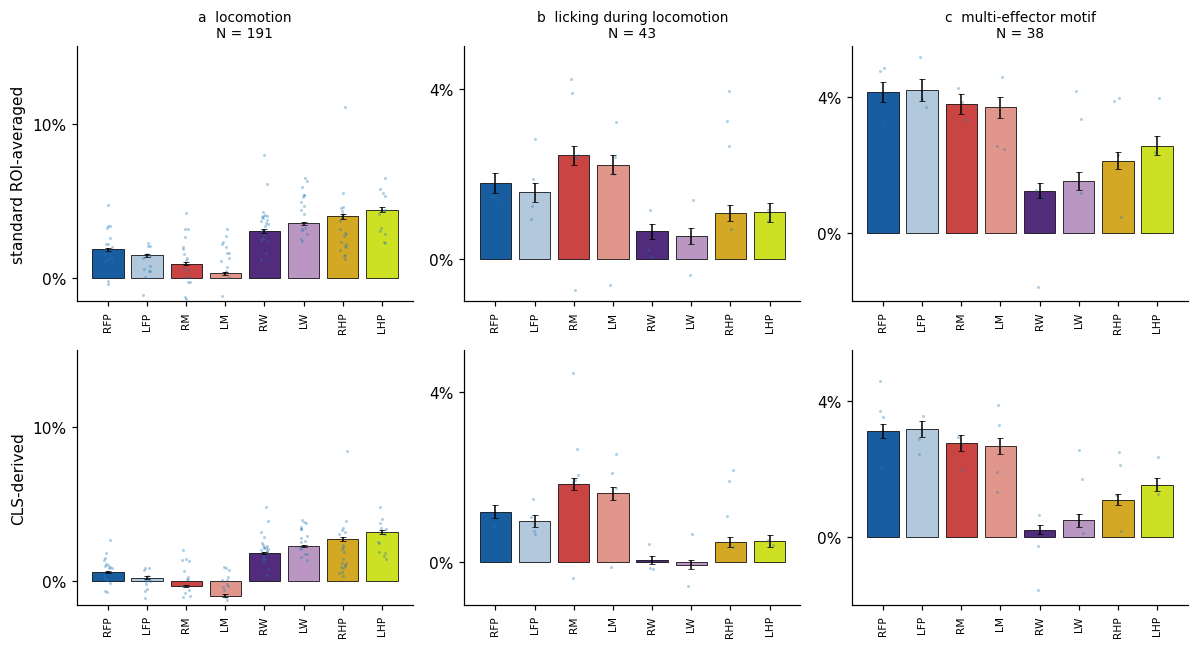

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), dpi=110)
for col, movement in enumerate(('run', 'lick', 'integrated')):
    for row, panel in enumerate(('i', 'ii')):
        ax = axes[row, col]
        amp, _ = amplitudes(movement, panel)
        df = long_form(amp)
        random.seed(0)
        down = df.iloc[random.sample(range(len(df)), int(len(df) * 0.25))]
        sns.barplot(ax=ax, data=df, x='bdp', y='value', order=M2_ORDER,
                    palette=palatte_dict, errorbar=None, zorder=1)
        sns.stripplot(ax=ax, data=down.iloc[::3, :], x='bdp', y='value', order=M2_ORDER,
                      color='tab:blue', size=2, jitter=True, zorder=3, alpha=0.35)
        for bar in ax.patches:
            bar.set_edgecolor('black'); bar.set_linewidth(0.5); bar.set_zorder(2)
        for i, bdp in enumerate(M2_ORDER):
            v = df[df['bdp'] == bdp]['value']
            ax.errorbar(i, v.mean(), yerr=v.sem(), fmt='none', ecolor='black',
                        capsize=2, capthick=0.5, linewidth=1, zorder=4)
        ax.set_ylim(YAXIS[movement]['ylim'])
        ax.set_yticks(YAXIS[movement]['yticks'])
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
        ax.set_xlabel(''); ax.set_ylabel('standard ROI-averaged' if (col == 0 and row == 0)
                                         else ('CLS-derived' if (col == 0 and row == 1) else ''))
        ax.tick_params(axis='x', rotation=90, labelsize=7)
        if row == 0:
            N = sum(a.shape[1] for a in amp.values())
            ax.set_title(f'{PANEL_LABEL[movement]}\nN = {N}', fontsize=9)
        for spine in ['top', 'right']:
            ax.spines[spine].set_linewidth(0)
plt.tight_layout()
plt.show()

---

## Appendix -- recomputing `TCs_matrix` for integrated cm128

Only needed if `figures_data/figureS9/TCs_matrix_integrated_cm128` is missing; the cell below
is guarded and will skip when the cached file is present. **It reads raw `step_1` data, not
`movie8`.**

`TCs_matrix` is the ROI-average *input* to the NNLS fit, so this does **not** refit the CLS
model -- it runs the `CLS-VALIDATION` notebook's own cells up to and including its
"append MEAN tc" cell, then applies that notebook's reshape/slice
(`reshape(42, B, T).transpose(0, 2, 1)[:, 0:58, :]`).

**This procedure was validated against ground truth**: run identically for cm126, it
reproduced that mouse's authoritative `TCs_matrix` to `max |diff| = 5.6e-17` (floating-point
noise). CHECK 3 above independently confirms the cm128 result holds the right bouts over the
right window.

A few cells fail and are skipped -- cm128 cell 33 raises `KeyError: 'RM'` (a QA plot
referencing an index not set until cell 42) and, for cm126, cells 42-43 hit a stale
`steps_data/figure/mask_midline_*.mat` path and its dependent. None of them define anything
`TCs_matrix` needs, and the cell hard-asserts that every genuine input is present.

In [13]:
import glob, json, os

def recompute_TCs_matrix(mouse, movement='integrated', verbose=True):
    '''Recompute TCs_matrix from raw step_1 via the CLS-VALIDATION notebook's own cells.'''
    vdir = CODE / 'make_0_prepare' / 'CLS-VALIDATION' / 'forward_pass_validation' / mouse
    hits = [h for h in glob.glob(str(vdir / f'*step2-{movement}*.ipynb')) if 'checkpoint' not in h]
    assert hits, f'no CLS-VALIDATION notebook for {mouse}/{movement}'
    nb_cells = json.loads(Path(hits[0]).read_text())['cells']

    i_build = next(i for i, c in enumerate(nb_cells) if 'TCs_matrix = np.empty' in ''.join(c['source']))
    i_append = next(i for i in range(i_build + 1, len(nb_cells))
                    if 'append MEAN tc' in ''.join(nb_cells[i]['source']))
    if verbose:
        print(f'{mouse}/{movement}: {Path(hits[0]).name} -- running cells 0..{i_append}')

    cwd = os.getcwd()
    real_fig_savefig, real_show = plt.Figure.savefig, plt.show
    plt.Figure.savefig = lambda self, *a, **k: None   # never overwrite a published SVG
    plt.show = lambda *a, **k: None
    os.chdir(vdir)
    ns, skipped = {'__name__': '__main__'}, []
    try:
        for i in range(0, i_append + 1):
            c = nb_cells[i]
            if c['cell_type'] != 'code':
                continue
            src = ''.join(c['source'])
            if not src.strip():
                continue
            try:
                exec(compile(src, f'cell{i}', 'exec'), ns)
            except Exception as e:                       # QA/plot-only cells -- see markdown above
                skipped.append((i, f'{type(e).__name__}: {e}'))
            plt.close('all')
    finally:
        os.chdir(cwd)
        plt.Figure.savefig, plt.show = real_fig_savefig, real_show

    if verbose and skipped:
        for i, err in skipped:
            print(f'    skipped cell {i}: {err[:90]}')

    for need in ('TCs_matrix', 'full_jrgeco', 'concat_H', 'concat_full_jrgeco',
                 'sensory_ind', 'M1_ind_from_coherence', 'seed_ROI_xy'):
        assert need in ns, f'{mouse}: a skipped cell dropped a required input: {need}'

    T, fj = ns['TCs_matrix'], ns['full_jrgeco']
    n_bouts, n_time = fj.shape[-1], fj.shape[-2]
    assert T.shape[0] == 42, f'{mouse}: {T.shape[0]} rows, expected 42 (did the append cell run?)'
    assert T.shape[1] == n_bouts * n_time, f'{mouse}: {T.shape} vs full_jrgeco {fj.shape}'
    out = T.copy().reshape((42, n_bouts, n_time)).transpose((0, 2, 1))[:, range(0, 58), :]
    if verbose:
        print(f'    -> {out.shape}, NaN fraction {np.isnan(out).mean():.4f}')
    return out


cache = Path(f'{FIGURES}/figureS9/TCs_matrix_integrated_cm128')
if cache.exists():
    print(f'cached, skipping recompute: {cache}')
    print(f'  shape {np.asarray(load_pickle(str(cache))).shape}')
else:
    tcs_cm128 = recompute_TCs_matrix('cm128')
    cache.parent.mkdir(parents=True, exist_ok=True)
    save_pickle(tcs_cm128, str(cache))
    print(f'wrote {cache}  -- now re-run CHECK 3 above to validate it')

cached, skipping recompute: /Volumes/WX/scratch/figures_data/figureS9/TCs_matrix_integrated_cm128
  shape (42, 58, 7)
